### Imports

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import math 
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

### 1. Loading datasets

In [2]:
bike = pd.read_csv("../csv/bikes.csv")
types = pd.read_csv("../csv/bike_types.csv")
city = pd.read_csv("../csv/cities.csv")
station = pd.read_csv("../csv/stations.csv")
station_status = pd.read_csv("../csv/stations_status.csv")
trips = pd.read_csv("../csv/trips_small.csv")

The project contains six tables:
- bike: individual bicycles
- types: technical bike-type metadata
- city: bike-sharing schemes and their geographic metadata
- station: station metadata and capacity
- station_status: repeated station-state snapshots over time
- trips: individual journeys

### 2. Data understanding

In [3]:
def data_invent(data):
    """This function provides a basic understanding of the data
    It checks missing values,unique values,data types,duplicates 
    and provides descriptive statistics"""

    null = data.isna().sum()
    null_per = data.isna().mean() * 100
    shape = data.shape
    des = data.describe(include = 'all')
    #col_names = data.columns.to_list()
    #cat_col = data.select_dtypes('Object','bool').columns
    data_type = data.dtypes
    unique_val = data.nunique()
    duplicate = data.duplicated().sum()

    Inventory = pd.DataFrame(
        {
            'Data type': data_type,
            'Missing values': null,
            'Missing value in %': null_per,
            'Unique values': unique_val

        }
    )

    print(f"Shape of the dataframe is : {shape}\n")
    print(f"The duplicate rows are : {duplicate}\n")
    display(Inventory)
    print(f"\nThe descriptive statistics :")
    display(des.T)



### 3. Initial data interpretation

#### 3.1 Bikes dataframe

In [4]:
data_invent(bike)

Shape of the dataframe is : (88436, 3)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.0,88436
bike_type_id,int64,0,0.0,121
computer_id,int64,0,0.0,72278



The descriptive statistics :


,count,mean,std,min,25%,50%,75%,max
id,88436.0,2.873477e+05,2.623808e+05,2204.0,4.503350e+04,2.240695e+05,4.852165e+05,9.984990e+05
bike_type_id,88436.0,1.306397e+02,6.863118e+01,0.0,7.100000e+01,1.500000e+02,1.960000e+02,2.540000e+02
computer_id,88436.0,6.533541e+09,8.500256e+09,0.0,7.551012e+09,7.551068e+09,7.551120e+09,7.551011e+11


* The dataset contains exactly 88,436 unique id values and zero duplicate rows. 
* There are exactly 121 unique bike_type_id values. The dataframe has 0% missing values (NaNs) across all three columns. 
* While there are 88,436 bikes, there are only 72,278 unique computer_ids. The descriptive statistics show the minimum computer_id is 0.0. 

#### 3.2 Bike types dataframe

In [5]:
data_invent(types)

Shape of the dataframe is : (121, 9)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.000000,121
vehicle_image,object,30,24.793388,91
name,object,30,24.793388,46
description,object,70,57.851240,40
form_factor,object,30,24.793388,3
rider_capacity,float64,30,24.793388,2
propulsion_type,object,30,24.793388,2
max_range,float64,106,87.603306,1
battery_capacity,float64,99,81.818182,4



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,121.0,NaN,NaN,NaN,134.454545,77.73845,0.0,72.0,149.0,201.0,254.0
vehicle_image,91,91,https://static.nextbike.net/app/biketypes/type...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,91,46,Rower z fotelikiem dziecięcym,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,51,40,"DOLLY BIKES ""e-Dolly"" MaxDrive\r\n\r\n - BAFAN...",6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
form_factor,91,3,bicycle,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rider_capacity,91.0,NaN,NaN,NaN,1.230769,0.423659,1.0,1.0,1.0,1.0,2.0
propulsion_type,91,2,human,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max_range,15.0,NaN,NaN,NaN,60000.0,0.0,60000.0,60000.0,60000.0,60000.0,60000.0
battery_capacity,22.0,NaN,NaN,NaN,547.727273,61.638873,500.0,500.0,500.0,600.0,690.0


* The dataframe contains 121 records with exactly 121 unique id values and zero duplicate rows. We can use it as a primary key for joining with the bikes table.
* Exactly 30 rows (24.8%) are simultaneously missing fundamental attributes: vehicle_image, name, form_factor, rider_capacity, and propulsion_type. This can refer to unclassified or deleted bike configurations in the system. We will need to decide whether to impute these as "Unknown" or exclude them later.
* The high missing rates for battery_capacity (81.8%) and max_range (87.6%) are logical, as human-powered bikes do not possess these metrics. The descriptive statistics shows that the 15 non-null records for max_range all share the exact same value (60000.0). 
* There is a strong many-to-one relationship in the types. While there are 121 technical ids, there are only 46 unique commercial names and 3 form_factors. This suggests that many technical IDs simply represent similar hardware of the same fundamental bike model.
* The descriptive statistics highlight that bikes are designed for either 1 or 2 riders, and the electric bikes utilize just four standard battery sizes ranging tightly between 500 Wh and 690 Wh.

#### 3.3 City dataframe

In [6]:
data_invent(city)

Shape of the dataframe is : (267, 7)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.0,267
name,object,0,0.0,267
lat,float64,0,0.0,264
lon,float64,0,0.0,266
timezone,object,0,0.0,9
country,object,0,0.0,15
return_to_official_only,bool,0,0.0,2



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,267.0,NaN,NaN,NaN,496.985019,232.77276,1.0,314.0,537.0,691.5,858.0
name,267,267,Zagreb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,267.0,NaN,NaN,NaN,49.067596,4.155125,27.8154,47.82785,49.898,51.58975,57.6902
lon,267.0,NaN,NaN,NaN,12.154192,7.02984,-15.5182,8.30655,13.7446,16.8312,33.4535
timezone,267,9,Europe/Berlin,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,267,15,DE,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_to_official_only,267,2,True,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* The dataframe contains 267 records with 0% missing values across all columns and no duplicate rows. Both id and name are primary identifiers for the bike-sharing schemes.

*  While there are 267 distinct scheme names, there are only 264 unique lat values and 266 unique lon values. This slight discrepancy confirms that some bike-sharing schemes share the exact same approximate city center coordinates. 

* The return_to_official_only variable is a  boolean feature indicating whether bikes must be left at a station. This distinguishes between strictly station-based systems and those that permit free-floating behavior.

* The network spans 15 distinct countries and 9 time zones. The bounding coordinates—from a latitude of 27.8° to 57.7° and a longitude of -15.5° to 33.4°—confirm a broad footprint encompassing diverse European urban environments.

#### 3.4 Trips dataframe

In [7]:
data_invent(trips)

Shape of the dataframe is : (1161376, 13)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
bike_id,int64,0,0.000000,26424
city_id,int64,0,0.000000,185
time_start,float64,0,0.000000,312677
lon_start,float64,0,0.000000,72638
lat_start,float64,0,0.000000,52706
lon_end,float64,0,0.000000,100802
lat_end,float64,0,0.000000,72880
station_id_start,float64,89215,7.681836,3675
station_id_end,float64,121904,10.496514,4432
battery_start,float64,992844,85.488593,101



The descriptive statistics :


,count,mean,std,min,25%,50%,75%,max
bike_id,1161376.0,2.265793e+05,1.996392e+05,3.346000e+03,5.962500e+04,8.881000e+04,4.001430e+05,8.400540e+05
city_id,1161376.0,5.179235e+02,2.374043e+02,7.000000e+00,3.310000e+02,5.480000e+02,7.170000e+02,8.580000e+02
time_start,1161376.0,1.676599e+09,9.407677e+06,1.661525e+09,1.666845e+09,1.678902e+09,1.685627e+09,1.689458e+09
lon_start,1161376.0,1.143184e+01,7.320269e+00,-1.560567e+01,7.165686e+00,1.019364e+01,1.745811e+01,3.398531e+01
lat_start,1161376.0,4.941432e+01,3.707710e+00,2.774058e+01,4.717771e+01,5.027373e+01,5.174006e+01,5.708158e+01
lon_end,1161376.0,1.143162e+01,7.320443e+00,-1.560567e+01,7.165686e+00,1.018726e+01,1.745811e+01,3.398632e+01
lat_end,1161376.0,4.941407e+01,3.708131e+00,2.774058e+01,4.717771e+01,5.026997e+01,5.173991e+01,5.708158e+01
station_id_start,1072161.0,4.223439e+07,4.759018e+07,9.400000e+01,5.669128e+06,2.072905e+07,7.251972e+07,2.192360e+08
station_id_end,1039472.0,4.236450e+07,4.793164e+07,9.400000e+01,5.445517e+06,1.982877e+07,7.279031e+07,2.146129e+08
battery_start,168532.0,8.098870e+01,2.138419e+01,0.000000e+00,6.600000e+01,8.900000e+01,1.000000e+02,1.000000e+02


* The dataset contains 1,161,376 total trip records. The core spatial coordinates (lon_start, lat_start, lon_end, lat_end), temporal data (time_start), and routing metrics (duration, distance) contain zero missing values, providing a highly reliable foundation for geospatial mapping and time-series aggregation.

* station_id_start is missing for 89,215 records and station_id_end is missing for 121,904 records. A NULL station ID indicates a free-floating start or end. They tell us whether a user utilized an official dock or left the bicycle in an ad-hoc location.

* The battery_start and battery_end variables are missing roughly 85% of the dataset (over 992,000 records). This high sparsity is due to the electric bicycles. For the electric subset, the median battery drain per trip is approximately 6%.

* The descriptive statistics reveal a median trip duration of 720 seconds (12 minutes) and a median distance of roughly 1,346 meters (1.35 km). However, the maximum duration extends to 28,740 seconds (nearly 8 hours) and the maximum distance to roughly 20 kilometers. 

#### 3.5 Station dataframe

In [8]:
data_invent(station)

Shape of the dataframe is : (2932, 11)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.000000,2932
city_id,int64,0,0.000000,185
name,object,0,0.000000,2855
app_number,int64,0,0.000000,2914
terminal_type,object,587,20.020464,10
place_type,int64,0,0.000000,16
bike_racks,int64,0,0.000000,33
special_racks,int64,0,0.000000,11
rack_locks,float64,2932,100.000000,0
lon,float64,0,0.000000,2912



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,2932.0,NaN,NaN,NaN,41160199.68588,47737638.319212,94.0,3604443.25,25317899.5,56610782.5,219235987.0
city_id,2932.0,NaN,NaN,NaN,480.171555,242.781001,7.0,251.0,527.0,702.0,858.0
name,2932,2855,Dworzec PKP,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
app_number,2932.0,NaN,NaN,NaN,29985.9294,61868.290176,0.0,4918.75,7907.5,48798.25,999574.0
terminal_type,2345,10,sign,881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place_type,2932.0,NaN,NaN,NaN,3.760914,6.894175,0.0,0.0,0.0,0.0,27.0
bike_racks,2932.0,NaN,NaN,NaN,6.033424,6.495116,0.0,0.0,6.0,10.0,70.0
special_racks,2932.0,NaN,NaN,NaN,-0.011255,0.48682,-10.0,0.0,0.0,0.0,12.0
rack_locks,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lon,2932.0,NaN,NaN,NaN,13.172182,6.91427,-15.758277,8.156823,14.314387,17.488668,33.413632


* The id column contains exactly 2,932 unique values for the 2,932 rows, functioning as a perfect primary key. However, there are only 2,855 unique station names, indicating that approximately 77 stations share names. 

* The rack_locks column is entirely empty (NaN), meaning it provides zero predictive value and should be dropped during preprocessing. Furthermore, the terminal_type (indicating hardware generation) is missing for 587 stations (~20%). 

* The descriptive statistics reveal a large portion of stations (1,220 out of 2,932) have exactly 0 bike_racks. This implies that these are not physical docks, but rather virtual stations or designated geofenced parking zones for free-floating setups. 

* The presence of special_racks (charging docks) shows a heavy positive skew, with the vast majority of stations having 0 (up through the 75th percentile), but a maximum of 12. 

#### 3.6 Station status dataframe

In [9]:
data_invent(station_status)

Shape of the dataframe is : (2925967, 8)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
station_id,int64,0,0.0,2899
time,float64,0,0.0,392858
bikes,int64,0,0.0,185
booked_bikes,int64,0,0.0,40
bikes_available_to_rent,int64,0,0.0,185
free_racks,int64,0,0.0,68
free_special_racks,int64,0,0.0,38
maintenance,bool,0,0.0,2



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
station_id,2925967.0,NaN,NaN,NaN,40847532.8712,46421829.121629,94.0,6215911.0,19489795.0,59198047.0,219235987.0
time,2925967.0,NaN,NaN,NaN,1676530748.342377,9488314.781911,1661525281.0,1666616341.0,1678896961.0,1685642522.0,1689458341.0
bikes,2925967.0,NaN,NaN,NaN,6.186521,6.091899,0.0,3.0,5.0,8.0,189.0
booked_bikes,2925967.0,NaN,NaN,NaN,0.045999,0.402517,-4.0,0.0,0.0,0.0,38.0
bikes_available_to_rent,2925967.0,NaN,NaN,NaN,6.141577,6.099811,0.0,2.0,5.0,8.0,189.0
free_racks,2925967.0,NaN,NaN,NaN,5.0309,5.300172,0.0,0.0,4.0,8.0,70.0
free_special_racks,2925967.0,NaN,NaN,NaN,2.216036,4.342693,0.0,0.0,0.0,3.0,37.0
maintenance,2925967,2,False,2795425,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* With nearly 2.93 million snapshot records and absolutely zero null values across all eight columns.

* The time column is currently stored as a float64 UNIX timestamp. To make this useful it must be converted into Pandas datetime objects to find cyclical features such as hour-of-day, day-of-week, and weekday-vs-weekend.

*  The descriptive statistics show massive variance in station scale. While the median station has 4 free racks and 5 bikes available, the maximums stretch to 70 free racks and 189 available bikes. 

* The maintenance boolean flag indicates if a station is offline. 

### 4. Identifying relationships between tables

In [10]:
primary_key_checks = pd.DataFrame({
    "table": ["bike", "types", "city", "station"],
    "key": ["id", "id", "id", "id"],
    "rows": [len(bike), len(types), len(city), len(station)],
    "unique_key_values": [
        bike["id"].nunique(),
        types["id"].nunique(),
        city["id"].nunique(),
        station["id"].nunique()
    ]
})
primary_key_checks["unique_key"] = (
    primary_key_checks["rows"] == primary_key_checks["unique_key_values"]
)
display(primary_key_checks)

,table,key,rows,unique_key_values,unique_key
0,bike,id,88436,88436,True
1,types,id,121,121,True
2,city,id,267,267,True
3,station,id,2932,2932,True


In [11]:
def fk_check(child, child_col, parent, parent_col, label, allow_null=False):
    values = child[child_col]
    if allow_null:
        values = values.dropna()
    matched = values.isin(parent[parent_col])
    return {
        "relationship": label,
        "checked_values": len(values),
        "matched": int(matched.sum()),
        "unmatched": int((~matched).sum()),
        "match_percent": round(matched.mean() * 100, 3) if len(values) else np.nan
    }

fk_results = [
    fk_check(bike, "bike_type_id", types, "id", "bikes.bike_type_id -> bike_types.id"),
    fk_check(station, "city_id", city, "id", "stations.city_id -> cities.id"),
    fk_check(station_status, "station_id", station, "id", "station_status.station_id -> stations.id"),
    fk_check(trips, "bike_id", bike, "id", "trips.bike_id -> bikes.id"),
    fk_check(trips, "city_id", city, "id", "trips.city_id -> cities.id"),
    fk_check(trips, "station_id_start", station, "id", "trips.station_id_start -> stations.id", allow_null=True),
    fk_check(trips, "station_id_end", station, "id", "trips.station_id_end -> stations.id", allow_null=True)
]
fk_results = pd.DataFrame(fk_results)
display(fk_results)

,relationship,checked_values,matched,unmatched,match_percent
0,bikes.bike_type_id -> bike_types.id,88436,88436,0,100.000
1,stations.city_id -> cities.id,2932,2932,0,100.000
2,station_status.station_id -> stations.id,2925967,2925967,0,100.000
3,trips.bike_id -> bikes.id,1161376,1161376,0,100.000
4,trips.city_id -> cities.id,1161376,1161376,0,100.000
5,trips.station_id_start -> stations.id,1072161,1055459,16702,98.442
6,trips.station_id_end -> stations.id,1039472,963433,76039,92.685


In [12]:
stations_without_status = set(station["id"]) - set(station_status["station_id"])
status_station_ids_not_in_metadata = set(station_status["station_id"]) - set(station["id"])

print("Stations in metadata:", station["id"].nunique())
print("Stations represented in status:", station_status["station_id"].nunique())
print("Stations with no status observations:", len(stations_without_status))
print("Status station IDs absent from station metadata:", len(status_station_ids_not_in_metadata))

Stations in metadata: 2932
Stations represented in status: 2899
Stations with no status observations: 33
Status station IDs absent from station metadata: 0


### 5. Individual bikes and bike types

##### Number of individual bikes 

In [13]:
bike['id'].nunique()

88436

##### Number of unique bike types 

In [14]:
types['id'].nunique()

121

##### Distribution of bikes per type

In [15]:
bike_profile = bike.merge(
    types[["id", "name", "propulsion_type", "form_factor", "rider_capacity",
           "battery_capacity", "max_range"]],
    left_on="bike_type_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("_bike", "_type")
)

In [16]:
display(bike_profile["_merge"].value_counts())
bike_distribution = (
    bike_profile.groupby(["name", "propulsion_type"], dropna=False)
    .agg(
        individual_bikes=("id_bike", "count"),
        technical_type_ids=("bike_type_id", "nunique")
    )
    .sort_values("individual_bikes", ascending=False)
)
display(bike_distribution.head(20))

_merge
both          88436
left_only         0
right_only        0
Name: count, dtype: int64

,,individual_bikes,technical_type_ids
name,propulsion_type,,
with Framelock,human,41691,4
SMARTbike 2.0 (A) 2018,human,13375,1
with Fork lock,human,7227,1
CLASSICbike,human,5108,1
Comfort,human,4756,1
E-Bike,electric_assist,2729,4
3-rychlostní SMARTbike 2.0.,human,2547,3
Comfort 1 1/8 Zoll,human,1607,1
8-rychlostní SMARTbike,human,1558,2


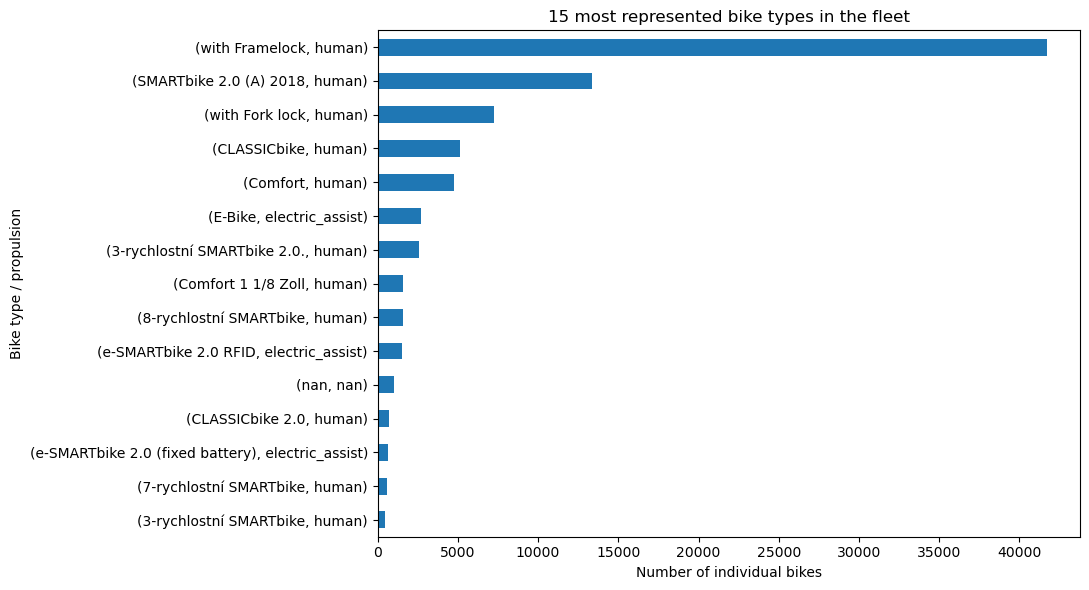

In [17]:
plt.figure(figsize=(11, 6))
bike_distribution.head(15)["individual_bikes"].sort_values().plot(kind="barh")
plt.title("15 most represented bike types in the fleet")
plt.xlabel("Number of individual bikes")
plt.ylabel("Bike type / propulsion")
plt.tight_layout()
plt.show()

### 5.2 Bike type characteristics

##### Propulsion type 

In [18]:
types['propulsion_type'].value_counts()

propulsion_type
human              64
electric_assist    27
Name: count, dtype: int64

##### Form factor

In [19]:
types.form_factor.value_counts()

form_factor
bicycle          71
cargo_bicycle    19
other             1
Name: count, dtype: int64

##### Rider capacity

In [20]:
types["rider_capacity"].value_counts(dropna=False).sort_index()

rider_capacity
1.0    70
2.0    21
NaN    30
Name: count, dtype: int64

##### Battery capacity and maximum range

In [21]:
types['battery_capacity'].unique()

array([ nan, 500., 630., 600., 690.])

In [22]:
types['max_range'].unique()

array([   nan, 60000.])

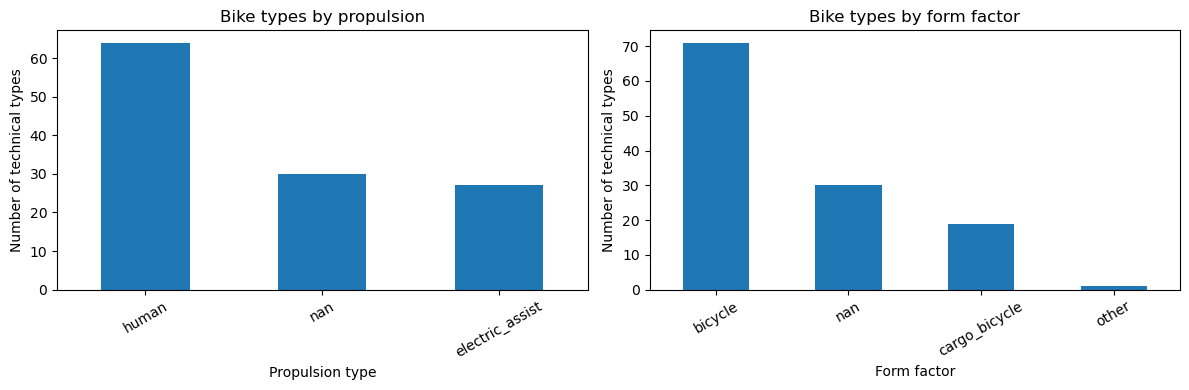

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
types["propulsion_type"].value_counts(dropna=False).plot(
    kind="bar", ax=axes[0], title="Bike types by propulsion"
)
types["form_factor"].value_counts(dropna=False).plot(
    kind="bar", ax=axes[1], title="Bike types by form factor"
)
axes[0].set_xlabel("Propulsion type")
axes[1].set_xlabel("Form factor")
for ax in axes:
    ax.set_ylabel("Number of technical types")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [24]:
display(types.groupby("propulsion_type", dropna=False).agg(
    type_records=("id", "count"),
    unique_names=("name", "nunique"),
    non_missing_battery=("battery_capacity", "count"),
    non_missing_range=("max_range", "count"),
    battery_values=("battery_capacity", lambda x: sorted(x.dropna().unique().tolist())),
    range_values=("max_range", lambda x: sorted(x.dropna().unique().tolist()))
))

,type_records,unique_names,non_missing_battery,non_missing_range,battery_values,range_values
propulsion_type,,,,,,
electric_assist,27,12,22,15,"[500.0, 600.0, 630.0, 690.0]",[60000.0]
human,64,34,0,0,[],[]
NaN,30,0,0,0,[],[]


In [25]:
name_reuse = (
    types.groupby("name", dropna=False)
    .agg(
        technical_ids=("id", "nunique"),
        propulsion_types=("propulsion_type", lambda x: x.nunique(dropna=False)),
        form_factors=("form_factor", lambda x: x.nunique(dropna=False))
    )
    .sort_values("technical_ids", ascending=False)
)
display(name_reuse.head(20))

,technical_ids,propulsion_types,form_factors
name,,,
NaN,30,1,1
Rower z fotelikiem dziecięcym,10,1,1
e-Cargobike,7,1,1
Tandem,7,1,1
Rowerek dziecięcy 6+,5,1,1
e-CARGObike,5,1,1
E-Bike,4,1,1
Cargo,4,1,1
with Framelock,4,1,1


### 5.3 Missingness in bike-type metadata

##### Missing descriptions

In [26]:
print(types['description'].isna().sum())
print(types['description'].isna().mean() * 100)

70
57.85123966942148


##### Relationship between propulsion type and missingness

In [27]:
types.groupby('propulsion_type').agg(
    total_types=('id', 'count'),
    missing_battery=('battery_capacity', lambda x: x.isna().sum()),
    missing_range=('max_range', lambda x: x.isna().sum())
)

,total_types,missing_battery,missing_range
propulsion_type,,,
electric_assist,27,5,12
human,64,64,64


In [28]:
core_type_columns = [
    "vehicle_image", "name", "form_factor",
    "rider_capacity", "propulsion_type"
]

missing_type_summary = pd.DataFrame({
    "missing_count": types[["description", "battery_capacity", "max_range"]].isna().sum(),
    "missing_percent": (types[["description", "battery_capacity", "max_range"]].isna().mean() * 100).round(2)
})
display(missing_type_summary)

,missing_count,missing_percent
description,70,57.85
battery_capacity,99,81.82
max_range,106,87.60


In [29]:
all_core_missing = types[core_type_columns].isna().all(axis=1)
any_core_missing = types[core_type_columns].isna().any(axis=1)
print("Rows with all five core attributes missing:", int(all_core_missing.sum()))
print("Rows with at least one core attribute missing:", int(any_core_missing.sum()))

Rows with all five core attributes missing: 30
Rows with at least one core attribute missing: 30


In [30]:
display(types.groupby("propulsion_type", dropna=False).agg(
    number_of_types=("id", "count"),
    battery_missing=("battery_capacity", lambda x: x.isna().sum()),
    battery_missing_percent=("battery_capacity", lambda x: x.isna().mean() * 100),
    range_missing=("max_range", lambda x: x.isna().sum()),
    range_missing_percent=("max_range", lambda x: x.isna().mean() * 100)
))

,number_of_types,battery_missing,battery_missing_percent,range_missing,range_missing_percent
propulsion_type,,,,,
electric_assist,27,5,18.518519,12,44.444444
human,64,64,100.000000,64,100.000000
NaN,30,30,100.000000,30,100.000000


In [31]:
missingness_by_propulsion = types.assign(
    battery_missing=types["battery_capacity"].isna(),
    range_missing=types["max_range"].isna()
).groupby("propulsion_type")[["battery_missing", "range_missing"]].mean() * 100

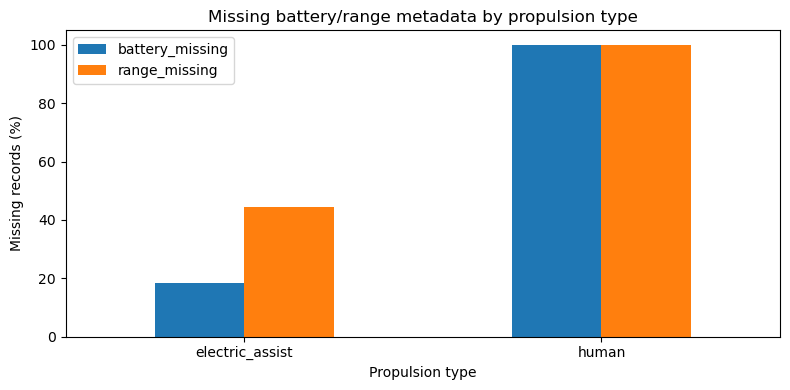

In [32]:
missingness_by_propulsion.plot(kind="bar", figsize=(8, 4))
plt.title("Missing battery/range metadata by propulsion type")
plt.ylabel("Missing records (%)")
plt.xlabel("Propulsion type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### 5.4 Key findings 

###### Important observations 

###### Limitations and preprocessing decisions

#### 5.5 City exploration

##### Distribution of bike-sharing schemes across countries.

In [33]:
city['country'].unique()

array(['HR', 'PL', 'AT', 'DE', 'MT', 'GB', 'CH', 'CZ', 'CY', 'ES', 'SI',
       'SK', 'SE', 'IT', 'LV'], dtype=object)

##### Number of schemes per country.

In [34]:
country_counts = city['country'].value_counts().sort_values(ascending=False)

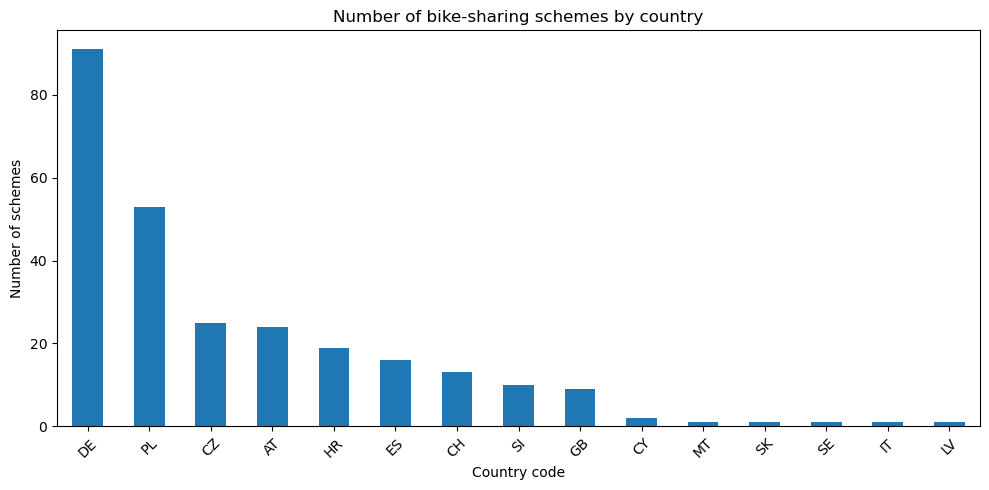

In [35]:
plt.figure(figsize=(10, 5))
country_counts.plot(kind="bar")
plt.title("Number of bike-sharing schemes by country")
plt.xlabel("Country code")
plt.ylabel("Number of schemes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Geographic coordinates and missing values.

In [36]:
city[['lat','lon']].value_counts()

lat      lon      
51.2469   22.56970    2
27.8154  -15.51820    1
50.9429   6.95649     1
50.9671   6.11886     1
51.0192   7.18025     1
                     ..
48.9429   8.39784     1
48.9620   8.29575     1
49.0102   8.41827     1
49.0678   17.46650    1
57.6902   11.98810    1
Name: count, Length: 266, dtype: int64

In [37]:
print("Unique schemes:", city["id"].nunique())
print("Unique countries:", city["country"].nunique())
print("Unique time zones:", city["timezone"].nunique())
print("Number of coordinate pairs shared by multiple schemes:", int((city.groupby(["lat", "lon"]).size() > 1).sum()))

Unique schemes: 267
Unique countries: 15
Unique time zones: 9
Number of coordinate pairs shared by multiple schemes: 1


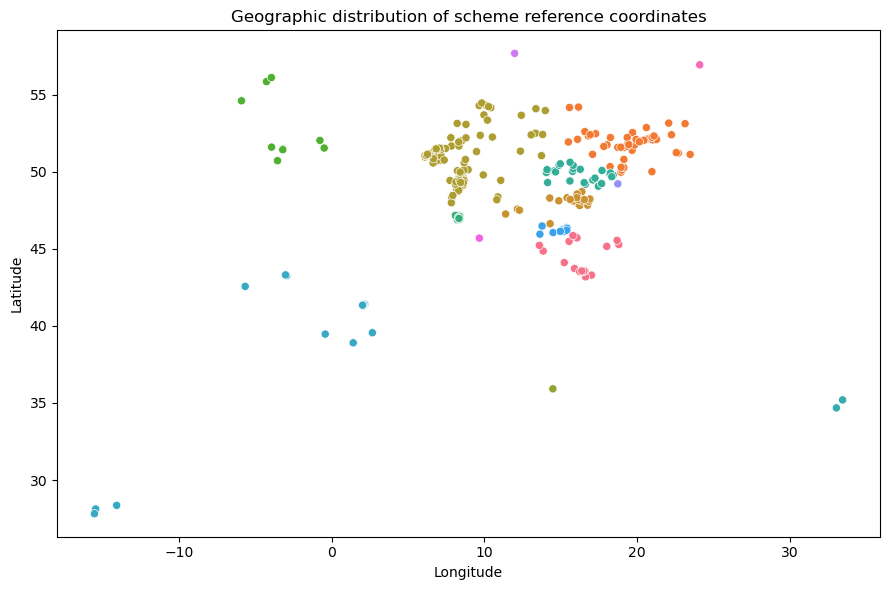

In [38]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=city, x="lon", y="lat", hue="country", legend=False, s=35)
plt.title("Geographic distribution of scheme reference coordinates")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

In [39]:
city[(city['lat'] == 51.2469) & (city['lon'] == 22.56970)] 

,id,name,lat,lon,timezone,country,return_to_official_only
35,251,Lublin,51.2469,22.5697,Europe/Warsaw,PL,True
241,729,Stacje Sponsorskie Nextbike LRM,51.2469,22.5697,Europe/Warsaw,PL,True


Both records have the same approximate city-centre coordinates, but they represent separate scheme records. This is not necessarily a duplicate or an error. It could be two schemes operating in the same geographical area

##### return_to_official_only distribution.

In [40]:
city['return_to_official_only'].value_counts()

return_to_official_only
True     200
False     67
Name: count, dtype: int64

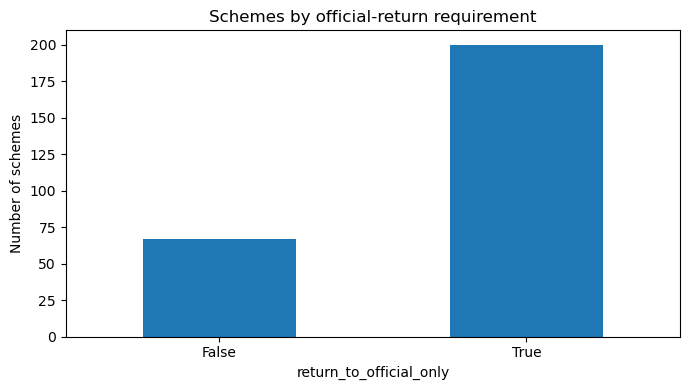

In [41]:
plt.figure(figsize=(7, 4))
city["return_to_official_only"].value_counts().sort_index().plot(kind="bar")
plt.title("Schemes by official-return requirement")
plt.xlabel("return_to_official_only")
plt.ylabel("Number of schemes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### City interpretation

#### 5.6 Station exploration

##### Number of stations

In [42]:
station['id'].nunique()

2932

##### Unique station names 

In [43]:
station['name'].unique()

array(['BIKE 500100', 'Bahnhof Trassenmoor 5525',
       'Mutter/Vater-Kind-Kurklinik Haus Möwennest Zinnowitz', ...,
       'Rheydt Hauptbahnhof', 'Elba Sara',
       'Bergheim, Quadrath-Ichendorf, Ahestraße'], dtype=object)

In [44]:
repeated_station_names = (
    station[station["name"].duplicated(keep=False)]
    .sort_values(["name", "city_id", "id"])
)
display(repeated_station_names[["id", "city_id", "name", "lon", "lat"]].head(50))

,id,city_id,name,lon,lat
293,72519774,431,Aquapark,18.102240,51.756890
1905,42613441,702,Aquapark,17.472689,49.066874
2794,16732370,523,Armii Krajowej,20.628990,52.872230
1514,10195053,562,Armii Krajowej,19.806997,51.740299
1527,10279700,564,Armii Krajowej,19.949966,52.114787
2362,29079072,220,Autobusni kolodvor,15.993288,45.804404
1014,2687297,248,Autobusni kolodvor,15.893569,43.731453
1200,687108,327,Autobusni kolodvor,15.241245,44.106828
137,61868135,747,BASF Agrarzentrum Limburgerhof,8.394231,49.413186
1140,120938456,747,BASF Agrarzentrum Limburgerhof,8.394670,49.412847


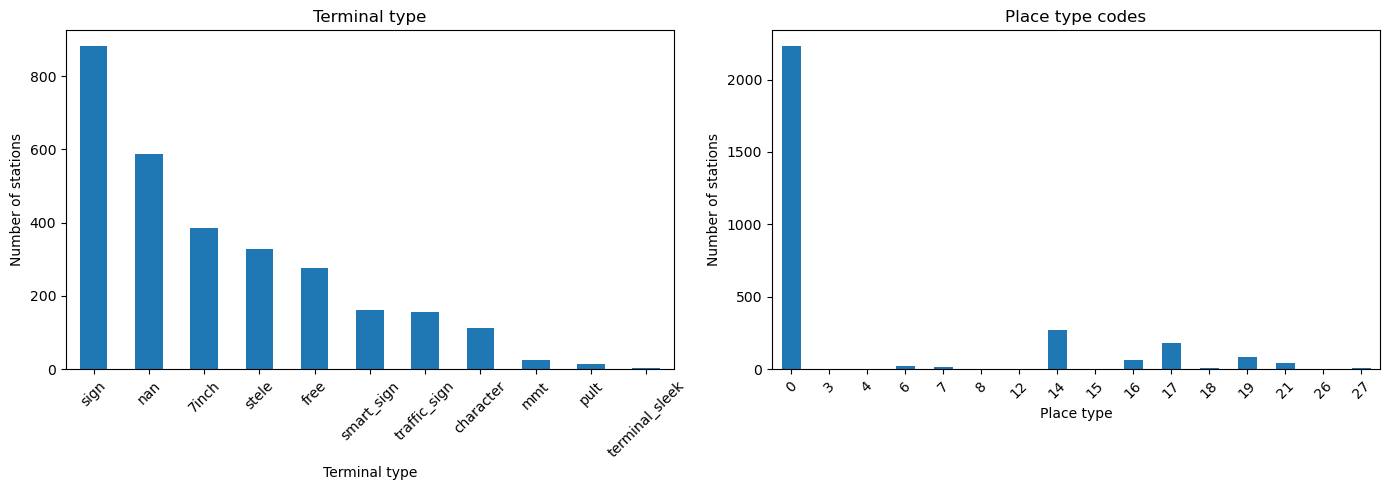

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
station["terminal_type"].value_counts(dropna=False).plot(kind="bar", ax=axes[0])
station["place_type"].value_counts(dropna=False).sort_index().plot(kind="bar", ax=axes[1])
axes[0].set_title("Terminal type")
axes[1].set_title("Place type codes")
axes[0].set_xlabel("Terminal type")
axes[1].set_xlabel("Place type")
for ax in axes:
    ax.set_ylabel("Number of stations")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [46]:
station['name'].value_counts()

name
Dworzec PKP                                11
Bahnhof                                     9
Rathaus                                     5
Rynek                                       5
Hauptbahnhof                                4
                                           ..
S.D. Stjepan Radić                          1
Point centar Vrbani                         1
Avenue Mall                                 1
Rougemarin Park                             1
Bergheim, Quadrath-Ichendorf, Ahestraße     1
Name: count, Length: 2855, dtype: int64

##### Distribution of terminal types and places

In [47]:
station['terminal_type'].value_counts()

terminal_type
sign              881
7inch             386
stele             329
free              276
smart_sign        162
traffic_sign      156
character         113
mmt                25
pult               14
terminal_sleek      3
Name: count, dtype: int64

In [48]:
station['place_type'].value_counts()

place_type
0     2229
14     269
17     182
19      87
16      64
21      39
6       24
7       12
18       9
27       6
12       3
8        2
15       2
4        2
26       1
3        1
Name: count, dtype: int64

In [49]:
station.groupby('terminal_type')['bike_racks'].count()

terminal_type
7inch             386
character         113
free              276
mmt                25
pult               14
sign              881
smart_sign        162
stele             329
terminal_sleek      3
traffic_sign      156
Name: bike_racks, dtype: int64

In [50]:
station.groupby(['bike_racks','terminal_type']).size()

bike_racks  terminal_type
0           7inch             11
            character          1
            free             229
            sign             255
            smart_sign        96
                            ... 
30          sign               1
36          sign               1
40          stele              2
56          sign               1
70          stele              2
Length: 136, dtype: int64

In [51]:
pd.crosstab(station['bike_racks'], station['terminal_type'])

terminal_type,7inch,character,free,mmt,pult,sign,smart_sign,stele,terminal_sleek,traffic_sign
bike_racks,,,,,,,,,,
0,11,1,229,0,0,255,96,20,0,130
1,0,0,0,0,0,1,0,1,0,0
2,2,0,0,0,0,1,2,3,0,0
3,2,1,2,0,0,6,0,2,0,3
4,20,4,14,0,3,25,9,21,0,0
5,10,1,18,1,5,66,0,4,0,1
6,62,12,2,0,2,56,23,72,1,14
7,1,0,3,17,0,6,1,7,0,0
8,29,15,2,4,0,43,8,44,0,5


##### Regular and special rack capacity

In [52]:
station[['bike_racks','special_racks']]

,bike_racks,special_racks
0,0,0
1,6,0
2,15,0
3,20,0
4,6,0
...,...,...
2927,11,0
2928,10,0
2929,9,0
2930,4,0


In [53]:
station['bike_racks'].value_counts()

bike_racks
0     1220
6      276
15     263
10     257
12     249
8      162
5      115
4      102
7       47
20      37
14      37
16      28
9       19
22      18
3       17
18      14
24      14
11      12
13      10
2        8
19       5
17       5
30       3
70       2
40       2
1        2
21       2
56       1
26       1
29       1
36       1
25       1
27       1
Name: count, dtype: int64

##### Zero rack stations

In [54]:
station[station['bike_racks'] == 0]

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
10,110473405,629,FORMENTERA,3865,NaN,0,0,0,NaN,1.434906,38.912460
12,130175397,184,Gmünd / WK,355300,NaN,0,0,0,NaN,14.979298,48.768507
14,81369035,134,Wissenschaftspark Gelsenkirchen,7580,free,0,0,0,NaN,7.107439,51.497658
15,75832440,767,Lipůvka,48537,sign,0,0,0,NaN,16.552767,49.339050
...,...,...,...,...,...,...,...,...,...,...,...
2917,149878288,794,Borsteler Weg,2180,free,0,0,0,NaN,10.214882,53.348598
2920,4775113,7,Herderstraße,5187,free,0,0,0,NaN,8.233523,50.074514
2925,78685267,768,ZOO,49039,NaN,0,0,0,NaN,15.799026,50.435022
2926,104996679,768,Sylvárov,49054,NaN,0,0,0,NaN,15.814112,50.418406


#### Comparing zero rack and non zero rack stations 

In [55]:
station_status_with_capacity = station_status.merge(
    station[["id", "bike_racks", "special_racks", "terminal_type", "place_type"]],
    left_on="station_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

In [56]:
station_status_with_capacity["zero_regular_racks"] = (
    station_status_with_capacity["bike_racks"] == 0
)

In [57]:
zero_rack_status_comparison = station_status_with_capacity.groupby(
    "zero_regular_racks"
).agg(
    status_observations=("station_id", "size"),
    stations=("station_id", "nunique"),
    mean_bikes=("bikes", "mean"),
    mean_available=("bikes_available_to_rent", "mean"),
    zero_available_percent=("bikes_available_to_rent", lambda x: (x == 0).mean() * 100),
    mean_free_regular_racks=("free_racks", "mean"),
    mean_free_special_racks=("free_special_racks", "mean")
)

In [58]:
display(zero_rack_status_comparison)

,status_observations,stations,mean_bikes,mean_available,zero_available_percent,mean_free_regular_racks,mean_free_special_racks
zero_regular_racks,,,,,,,
False,2188761,1694,6.470897,6.439287,4.736150,6.69839,2.938783
True,737206,1205,5.342208,5.257677,8.567754,0.08013,0.070202


In [59]:
del station_status_with_capacity

##### Missing coordinates

In [60]:
station[['lon','lat']].isna().sum()

lon    0
lat    0
dtype: int64

#### Station infrastructure interpretation

#### 5.7 City Station integration

##### Merging stations with cities

In [61]:
station_city = station.merge(
    city,
    left_on='city_id',
    right_on='id',
    how='left',
    suffixes=('_station', '_city'),
    validate='many_to_one',
    indicator=True
)

station_city['_merge'].value_counts()

_merge
both          2932
left_only        0
right_only       0
Name: count, dtype: int64

In [62]:
unmatched_station_city = station_city.loc[
    station_city["_merge"] != "both",
    ["id_station", "city_id", "name_station"]
]
display(unmatched_station_city)

,id_station,city_id,name_station


In [63]:
station_city[station_city['_merge'] != 'both']

,id_station,city_id,name_station,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon_station,lat_station,id_city,name_city,lat_city,lon_city,timezone,country,return_to_official_only,_merge


##### Number of stations per schema 

In [64]:
stations_per_city = (
    station_city.groupby(['city_id', 'name_city'])
    .agg(number_of_stations=('id_station', 'count'))
    .sort_values('number_of_stations', ascending=False)
)

stations_per_city.head(15)

,,number_of_stations
city_id,name_city,
251,Lublin,121
817,Mobic,121
176,Usedom,89
680,Pardubice,61
206,Nicosia,60
302,Malta,57
648,RVK e-Bike,52
706,Eifel e-Bike,51
396,Klagenfurt,49


##### Total rack capacity per schema 

In [65]:
capacity_per_city = (
    station_city.groupby(['city_id', 'name_city'])
    .agg(
        total_regular_racks=('bike_racks', 'sum'),
        total_special_racks=('special_racks', 'sum'),
        number_of_stations=('id_station', 'count')
    )
    .sort_values('total_regular_racks', ascending=False)
)

capacity_per_city.head(15)

,,total_regular_racks,total_special_racks,number_of_stations
city_id,name_city,,,
251,Lublin,1256,0,121
176,Usedom,818,0,89
557,Chorzów,655,0,44
775,MV-Rad,567,0,38
320,Milton Keynes,545,0,48
302,Malta,437,0,57
497,Sosnowiec,412,0,25
396,Klagenfurt,382,0,49
639,Orlen Płock,375,0,25


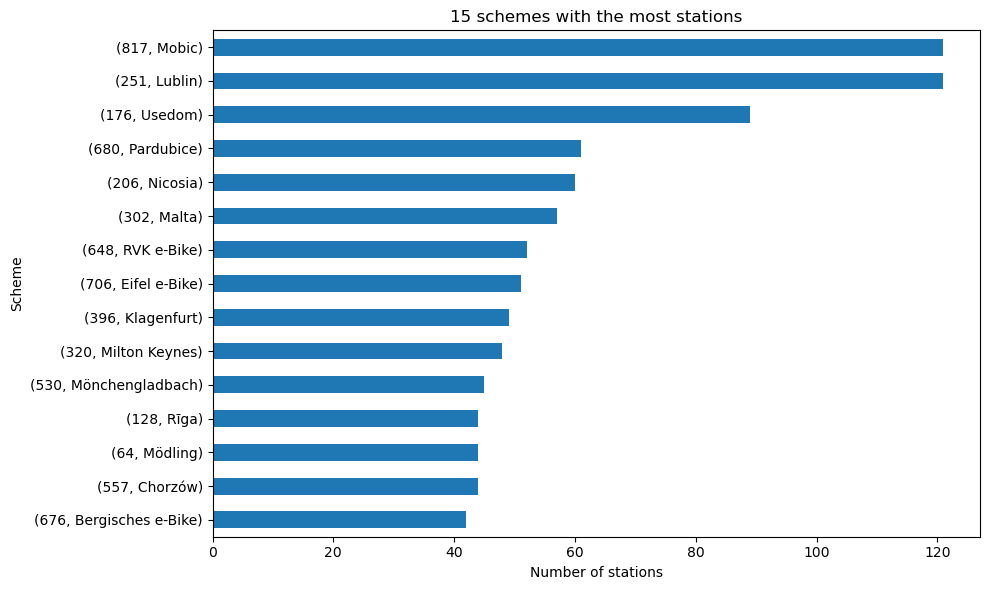

In [66]:
plt.figure(figsize=(10, 6))
stations_per_city.head(15)["number_of_stations"].sort_values().plot(kind="barh")
plt.title("15 schemes with the most stations")
plt.xlabel("Number of stations")
plt.ylabel("Scheme")
plt.tight_layout()
plt.show()

##### Average station capacity per schema

In [67]:
capacity_per_city = (
    station_city.groupby(["city_id", "name_city"])
    .agg(
        number_of_stations=("id_station", "nunique"),
        total_regular_racks=("bike_racks", "sum"),
        total_special_racks_raw=("special_racks", "sum"),
        mean_regular_racks=("bike_racks", "mean"),
        median_regular_racks=("bike_racks", "median"),
        stations_with_negative_special_racks=("special_racks", lambda x: (x < 0).sum())
    )
    .sort_values("total_regular_racks", ascending=False)
)
display(capacity_per_city.head(20))

,,number_of_stations,total_regular_racks,total_special_racks_raw,mean_regular_racks,median_regular_racks,stations_with_negative_special_racks
city_id,name_city,,,,,,
251,Lublin,121,1256,0,10.380165,15.0,0
176,Usedom,89,818,0,9.191011,8.0,0
557,Chorzów,44,655,0,14.886364,15.0,0
775,MV-Rad,38,567,0,14.921053,10.0,0
320,Milton Keynes,48,545,0,11.354167,8.0,0
302,Malta,57,437,0,7.666667,6.0,0
497,Sosnowiec,25,412,0,16.480000,12.0,0
396,Klagenfurt,49,382,0,7.795918,8.0,0
639,Orlen Płock,25,375,0,15.000000,15.0,0


In [68]:
station_city.groupby(['city_id', 'name_city']).agg(
    average_regular_racks=('bike_racks', 'mean'),
    median_regular_racks=('bike_racks', 'median'),
    average_special_racks=('special_racks', 'mean')
).sort_values('average_regular_racks', ascending=False)

,,average_regular_racks,median_regular_racks,average_special_racks
city_id,name_city,,,
550,Marki,22.000000,22.0,0.0
856,Sant Boi de Llobregat,20.000000,20.0,0.0
853,Sant Just Desvern,20.000000,21.0,0.0
848,Esplugues de Llobregat,19.636364,20.0,0.0
446,Szamotuły,17.714286,18.0,0.0
...,...,...,...,...
463,Sarnen,0.000000,0.0,0.0
752,Hlučín,0.000000,0.0,0.0
754,Oldenburg,0.000000,0.0,0.0


##### Zero rack station properties by schema

In [69]:
zero_rack_analysis = (
    station_city.assign(
        zero_rack=station_city['bike_racks'].eq(0)
    )
    .groupby(['city_id', 'name_city'])
    .agg(
        total_stations=('id_station', 'count'),
        zero_rack_stations=('zero_rack', 'sum')
    )
)

In [70]:
zero_rack_analysis['zero_rack_percentage'] = (
    100 * zero_rack_analysis['zero_rack_stations']
    / zero_rack_analysis['total_stations']
)

In [71]:
zero_rack_analysis.sort_values('zero_rack_percentage', ascending=False)

,,total_stations,zero_rack_stations,zero_rack_percentage
city_id,name_city,,,
858,Tecklenburg,18,18,100.0
680,Pardubice,61,61,100.0
213,WienerWald,5,5,100.0
678,Landau in der Pfalz,14,14,100.0
647,Graben,2,2,100.0
...,...,...,...,...
558,Heddesheim,4,0,0.0
557,Chorzów,44,0,0.0
308,Slavonski Brod,3,0,0.0


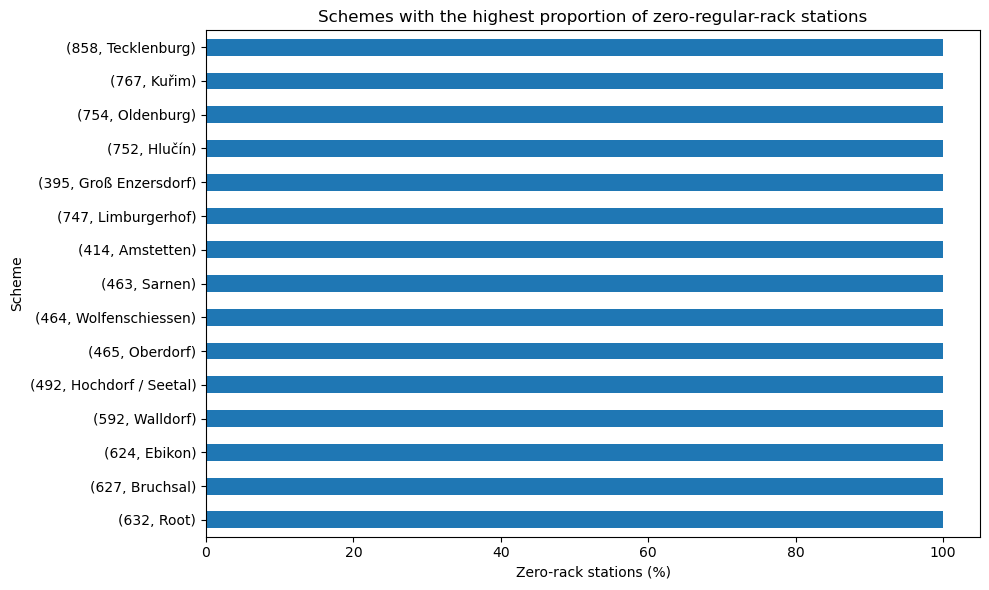

In [72]:
plt.figure(figsize=(10, 6))
zero_rack_analysis.sort_values("zero_rack_percentage").tail(15)[
    "zero_rack_percentage"
].plot(kind="barh")
plt.title("Schemes with the highest proportion of zero-regular-rack stations")
plt.xlabel("Zero-rack stations (%)")
plt.ylabel("Scheme")
plt.tight_layout()
plt.show()

#### City Station interpretation

#### 5.8 Station status infrastructure analysis

In [73]:
maintenance_analysis = station_status.groupby('maintenance').agg(
    observations=('station_id', 'size'),
    mean_bikes=('bikes', 'mean'),
    mean_booked=('booked_bikes', 'mean'),
    mean_available=('bikes_available_to_rent', 'mean'),
    zero_available=(
        'bikes_available_to_rent',
        lambda x: (x == 0).mean() * 100
    )
)

maintenance_analysis

,observations,mean_bikes,mean_booked,mean_available,zero_available
maintenance,,,,,
False,2795425,6.188272,0.047497,6.141872,5.772074
True,130542,6.149025,0.013919,6.135251,4.190988


In [74]:
expected_available = np.maximum(
    station_status['bikes'] -
    station_status['booked_bikes'],
    0
)

comparison = (
    station_status['bikes_available_to_rent']
    == expected_available
)

comparison.value_counts()

True     2925902
False         65
Name: count, dtype: int64

In [75]:
station_status.loc[
    ~comparison,
    [
        'station_id', 'time', 'bikes',
        'booked_bikes', 'bikes_available_to_rent',
        'maintenance'
    ]
]

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,maintenance
1419140,2591849,1.678257e+09,5,1,5,False
1419141,50458,1.678257e+09,5,3,4,False
1419146,54635,1.678257e+09,5,2,5,False
1419153,54635,1.678257e+09,5,3,5,False
1419174,54635,1.678257e+09,5,4,4,False
...,...,...,...,...,...,...
1422937,142154767,1.678302e+09,5,1,5,False
1423447,142154767,1.678314e+09,5,1,5,False
1423684,51003977,1.678336e+09,5,1,5,False
1423687,51003977,1.678336e+09,5,1,5,False


In [76]:
negative_bookings = station_status[
    station_status['booked_bikes'] < 0
]

negative_bookings.groupby('maintenance').size()

maintenance
False    154
True       6
dtype: int64

In [77]:
status_capacity = station_status.merge(
    station[['id', 'bike_racks', 'special_racks']],
    left_on='station_id',
    right_on='id',
    how='left',
    validate='many_to_one'
)

In [78]:
status_capacity['declared_capacity'] = (
    status_capacity['bike_racks']
    + status_capacity['special_racks']
)

status_capacity['observed_occupied_and_free'] = (
    status_capacity['bikes']
    + status_capacity['free_racks']
    + status_capacity['free_special_racks']
)

status_capacity['capacity_difference'] = (
    status_capacity['declared_capacity']
    - status_capacity['observed_occupied_and_free']
)

status_capacity['capacity_difference'].describe()

count    2.925967e+06
mean    -3.780645e+00
std      6.810545e+00
min     -1.890000e+02
25%     -6.000000e+00
50%     -2.000000e+00
75%      0.000000e+00
max      2.900000e+01
Name: capacity_difference, dtype: float64

#### 5.9 Station status temporal analysis 

In [79]:
station_status['datetime'] = pd.to_datetime(
    station_status['time'],
    unit='s',
    utc=True
)

print(station_status['datetime'].min())
print(station_status['datetime'].max())

2022-08-26 14:48:01+00:00
2023-07-15 21:59:01+00:00


In [80]:
print("Time span:", station_status["datetime"].max() - station_status["datetime"].min())
print("Unique stations in status:", station_status["station_id"].nunique())
print("Duplicate station-time rows:",
      station_status.duplicated(["station_id", "time"]).sum())

Time span: 323 days 07:11:00
Unique stations in status: 2899
Duplicate station-time rows: 0


In [81]:
status = station_status.sort_values(
    ['station_id', 'time']
).copy()

status['time_diff_minutes'] = (
    status.groupby('station_id')['time'].diff() / 60
)

status['time_diff_minutes'].describe()

count    2.923068e+06
mean     3.665869e+02
std      3.416895e+03
min      8.000000e-01
25%      4.000000e+00
50%      2.800000e+01
75%      1.580000e+02
max      4.147360e+05
Name: time_diff_minutes, dtype: float64

In [82]:
station_frequency = status.groupby('station_id').agg(
    observations=('time', 'count'),
    median_interval=('time_diff_minutes', 'median'),
    mean_interval=('time_diff_minutes', 'mean')
)

station_frequency.describe().T

,count,mean,std,min,25%,50%,75%,max
observations,2899.0,1009.302173,1678.189339,1.0,159.000000,427.000000,1099.500000,16643.0
median_interval,2892.0,543.201922,2511.697487,1.0,57.500000,155.750000,398.750000,80120.0
mean_interval,2892.0,2029.832845,4496.716904,1.0,330.237663,793.208309,2024.189945,80120.0


In [83]:
status.duplicated(
    subset=['station_id', 'time']
).sum()

0

In [84]:
status_intervals = status["time_diff_minutes"].dropna().copy()
intervals = status_intervals
del status

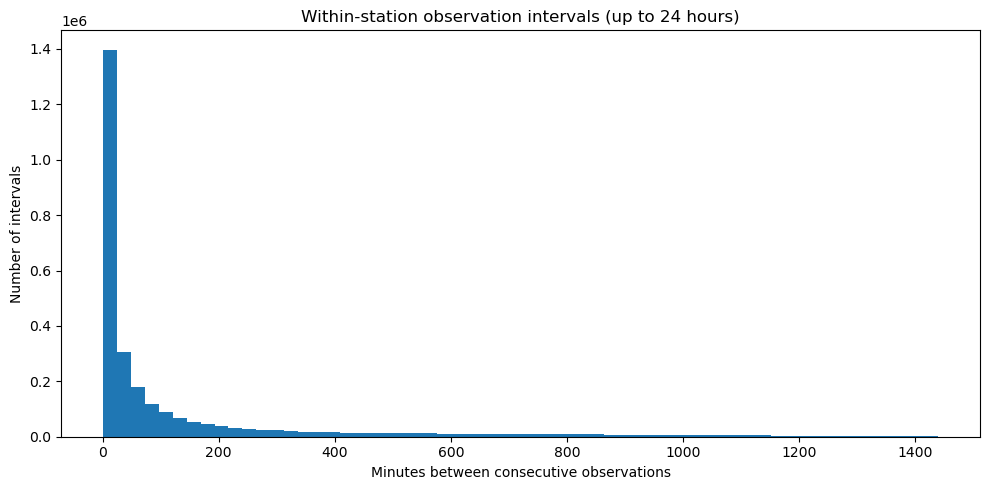

In [85]:
plt.figure(figsize=(10, 5))
plt.hist(intervals[intervals <= 24 * 60], bins=60)
plt.title("Within-station observation intervals (up to 24 hours)")
plt.xlabel("Minutes between consecutive observations")
plt.ylabel("Number of intervals")
plt.tight_layout()
plt.show()

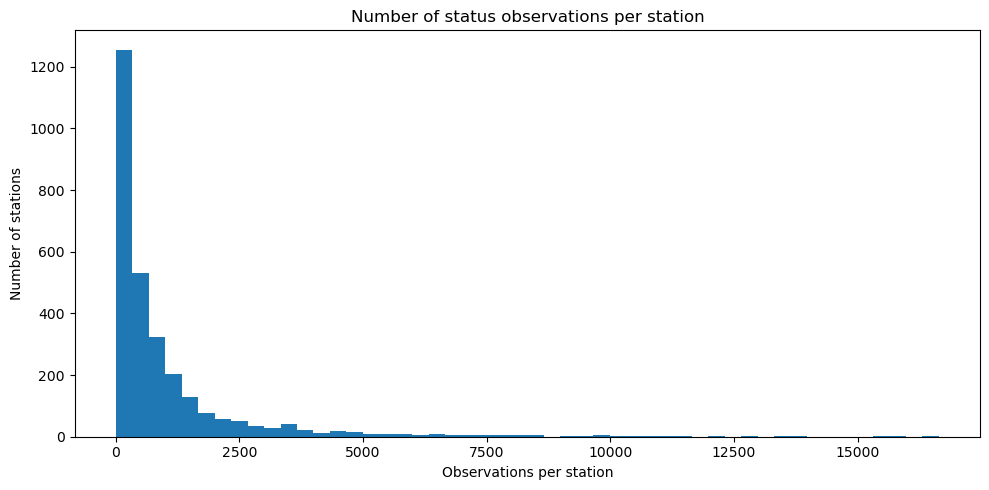

In [86]:
plt.figure(figsize=(10, 5))
plt.hist(station_frequency["observations"], bins=50)
plt.title("Number of status observations per station")
plt.xlabel("Observations per station")
plt.ylabel("Number of stations")
plt.tight_layout()
plt.show()

In [87]:
station_status["month"] = station_status["datetime"].dt.to_period("M").astype(str)
station_status["hour_utc"] = station_status["datetime"].dt.hour
station_status["weekday_utc"] = station_status["datetime"].dt.day_name()

/var/folders/qp/vwvz5t5x67b8cp19vx8yc7km0000gn/T/ipykernel_2895/3284830717.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  station_status["month"] = station_status["datetime"].dt.to_period("M").astype(str)


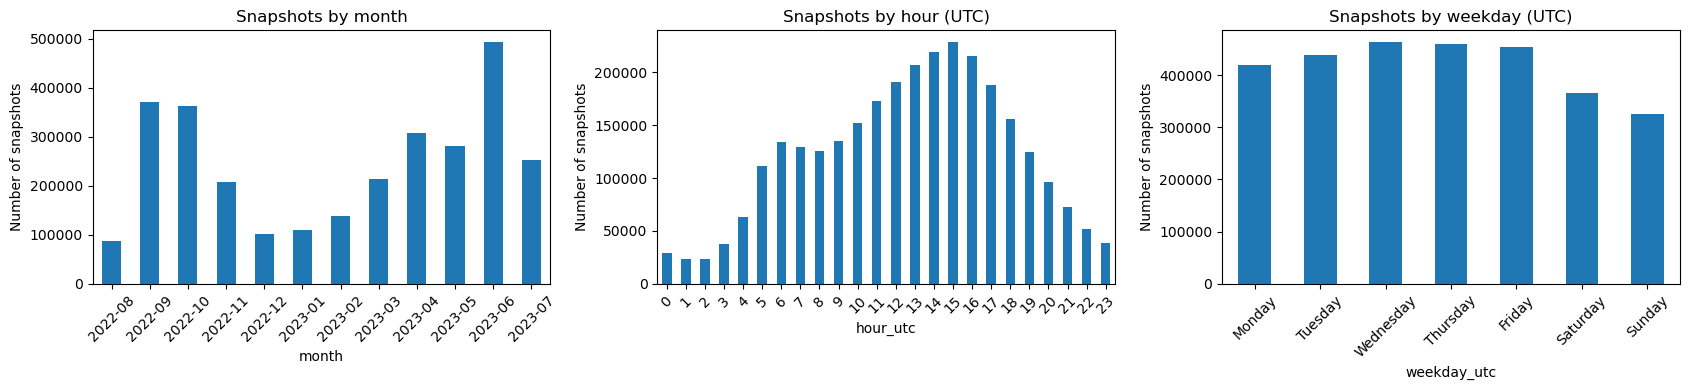

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
station_status["month"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
station_status["hour_utc"].value_counts().sort_index().plot(kind="bar", ax=axes[1])
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
station_status["weekday_utc"].value_counts().reindex(weekday_order).plot(kind="bar", ax=axes[2])
axes[0].set_title("Snapshots by month")
axes[1].set_title("Snapshots by hour (UTC)")
axes[2].set_title("Snapshots by weekday (UTC)")
for ax in axes:
    ax.set_ylabel("Number of snapshots")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

#### Temporal interpretation

#### 5.10 Station status relationships

#### Correlation between station status measurements

In [89]:
status_numeric_columns = [
    "bikes", "booked_bikes", "bikes_available_to_rent",
    "free_racks", "free_special_racks"
]
status_correlations = station_status[status_numeric_columns].corr()
display(status_correlations)

,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks
bikes,1.000000,0.010393,0.997925,-0.104465,0.057923
booked_bikes,0.010393,1.000000,-0.053644,-0.018085,-0.044238
bikes_available_to_rent,0.997925,-0.053644,1.000000,-0.103170,0.060706
free_racks,-0.104465,-0.018085,-0.103170,1.000000,0.587193
free_special_racks,0.057923,-0.044238,0.060706,0.587193,1.000000


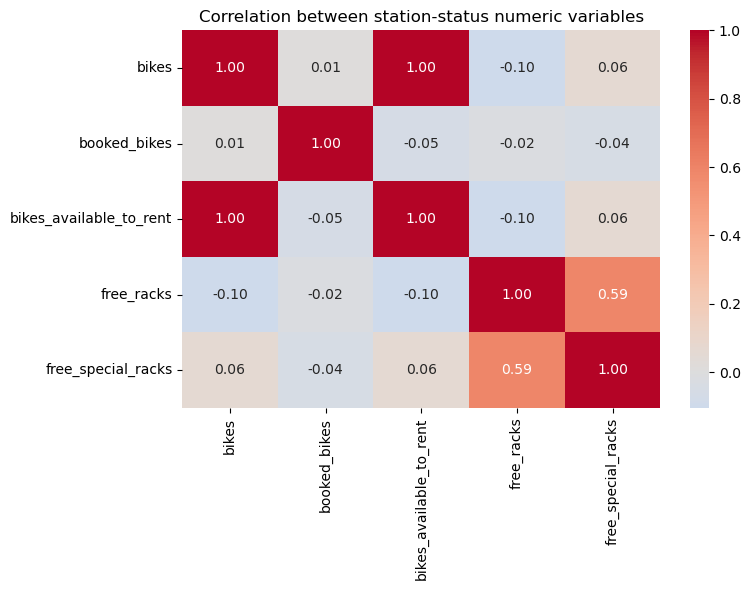

In [90]:
plt.figure(figsize=(8, 6))
sns.heatmap(status_correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between station-status numeric variables")
plt.tight_layout()
plt.show()

In [91]:
maintenance_summary = station_status.groupby("maintenance").agg(
    observations=("station_id", "size"),
    mean_bikes=("bikes", "mean"),
    mean_booked_bikes=("booked_bikes", "mean"),
    mean_available=("bikes_available_to_rent", "mean"),
    median_available=("bikes_available_to_rent", "median"),
    zero_available_percent=("bikes_available_to_rent", lambda x: (x == 0).mean() * 100)
)
display(maintenance_summary)

,observations,mean_bikes,mean_booked_bikes,mean_available,median_available,zero_available_percent
maintenance,,,,,,
False,2795425,6.188272,0.047497,6.141872,5.0,5.772074
True,130542,6.149025,0.013919,6.135251,5.0,4.190988


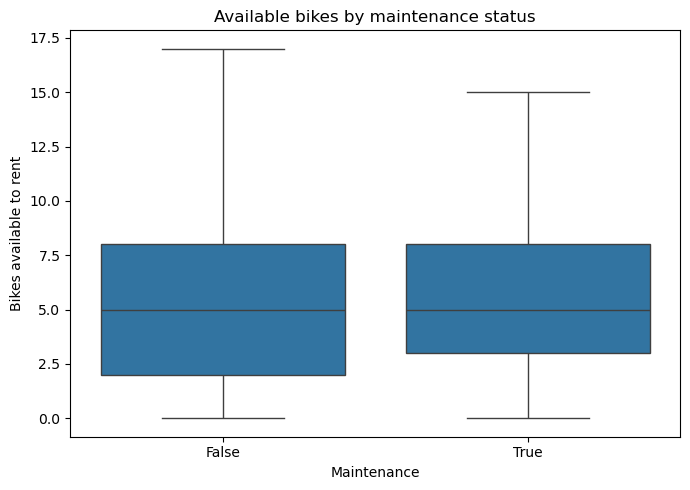

In [92]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=station_status, x="maintenance",
            y="bikes_available_to_rent", showfliers=False)
plt.title("Available bikes by maintenance status")
plt.xlabel("Maintenance")
plt.ylabel("Bikes available to rent")
plt.tight_layout()
plt.show()

In [93]:
raw_difference = station_status["bikes"] - station_status["booked_bikes"]
clamped_expected = raw_difference.clip(lower=0)

raw_match = station_status["bikes_available_to_rent"].eq(raw_difference)
clamped_match = station_status["bikes_available_to_rent"].eq(clamped_expected)

In [94]:
formula_comparison = pd.DataFrame({
    "comparison": ["bikes - booked_bikes", "max(bikes - booked_bikes, 0)"],
    "matching_rows": [int(raw_match.sum()), int(clamped_match.sum())],
    "non_matching_rows": [int((~raw_match).sum()), int((~clamped_match).sum())],
    "match_percent": [raw_match.mean() * 100, clamped_match.mean() * 100]
})
display(formula_comparison)

,comparison,matching_rows,non_matching_rows,match_percent
0,bikes - booked_bikes,2923631,2336,99.920163
1,"max(bikes - booked_bikes, 0)",2925902,65,99.997779


In [95]:
remaining_formula_cases = station_status.loc[
    ~clamped_match,
    ["station_id", "time", "bikes", "booked_bikes",
     "bikes_available_to_rent", "maintenance",
     "free_racks", "free_special_racks"]
]
display(remaining_formula_cases)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,maintenance,free_racks,free_special_racks
1419140,2591849,1.678257e+09,5,1,5,False,0,0
1419141,50458,1.678257e+09,5,3,4,False,5,0
1419146,54635,1.678257e+09,5,2,5,False,0,0
1419153,54635,1.678257e+09,5,3,5,False,0,0
1419174,54635,1.678257e+09,5,4,4,False,0,0
...,...,...,...,...,...,...,...,...
1422937,142154767,1.678302e+09,5,1,5,False,6,0
1423447,142154767,1.678314e+09,5,1,5,False,17,0
1423684,51003977,1.678336e+09,5,1,5,False,4,3
1423687,51003977,1.678336e+09,5,1,5,False,4,4


In [96]:
negative_bookings = station_status.loc[
    station_status["booked_bikes"] < 0
].copy()

print("Rows with negative booked_bikes:", len(negative_bookings))
display(negative_bookings.groupby("maintenance").size().rename("records"))
display(negative_bookings["booked_bikes"].value_counts().sort_index().rename("records_by_negative_code"))
display(negative_bookings[
    ["station_id", "time", "bikes", "booked_bikes",
     "bikes_available_to_rent", "free_racks",
     "free_special_racks", "maintenance"]
].head(30))

Rows with negative booked_bikes: 160


maintenance
False    154
True       6
Name: records, dtype: int64

booked_bikes
-4      5
-3      2
-2     33
-1    120
Name: records_by_negative_code, dtype: int64

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
29514,45914914,1.661699e+09,0,-1,1,12,11,False
30379,45914914,1.661702e+09,0,-1,1,12,12,False
122682,50476,1.662192e+09,1,-1,2,4,0,False
122694,50476,1.662192e+09,0,-1,1,5,0,False
122919,46614,1.662194e+09,3,-1,4,0,0,False
144823,43828727,1.662308e+09,5,-1,6,0,0,False
234863,45914961,1.662886e+09,3,-1,4,9,8,False
311016,30240427,1.663378e+09,0,-1,1,7,6,False
587339,113451,1.665684e+09,0,-1,1,6,0,False
587362,113451,1.665684e+09,1,-1,2,5,0,False


In [97]:
status_capacity = station_status.merge(
    station[["id", "bike_racks", "special_racks"]],
    left_on="station_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    indicator=True
)

In [98]:
status_capacity["declared_capacity_raw"] = (
    status_capacity["bike_racks"] + status_capacity["special_racks"]
)

In [99]:
status_capacity["observed_bikes_plus_free_racks"] = (
    status_capacity["bikes"] +
    status_capacity["free_racks"] +
    status_capacity["free_special_racks"]
)

In [100]:
status_capacity["capacity_difference_raw"] = (
    status_capacity["declared_capacity_raw"] -
    status_capacity["observed_bikes_plus_free_racks"]
)

In [101]:
print("Unmatched station metadata rows:", int((status_capacity["_merge"] != "both").sum()))
print("Stations with negative special_racks:", int((station["special_racks"] < 0).sum()))
print("Status rows with negative special-rack metadata:",
      int((status_capacity["special_racks"] < 0).sum()))
display(status_capacity["capacity_difference_raw"].describe())
display(status_capacity["capacity_difference_raw"].value_counts().head(20))
del status_capacity

Unmatched station metadata rows: 0
Stations with negative special_racks: 32
Status rows with negative special-rack metadata: 22194


count    2.925967e+06
mean    -3.780645e+00
std      6.810545e+00
min     -1.890000e+02
25%     -6.000000e+00
50%     -2.000000e+00
75%      0.000000e+00
max      2.900000e+01
Name: capacity_difference_raw, dtype: float64

capacity_difference_raw
 0     886042
-2     194536
-3     179426
-1     175245
-4     172475
-5     157170
-6     126727
-7     113082
-8     101856
 1      92644
-9      85651
-10     74567
-11     63820
 2      62241
-12     54362
-13     44853
-14     35032
 4      34852
 3      33810
-15     27613
Name: count, dtype: int64

#### Status consistency interpretation 

#### 5.11 Trip exploration

##### Trip data validity and relationship between duration and distance

In [102]:
trip_validity = pd.Series({
    "duration_nonpositive": (trips["duration"] <= 0).sum(),
    "distance_nonpositive": (trips["distance"] <= 0).sum(),
    "invalid_start_longitude": (~trips["lon_start"].between(-180, 180)).sum(),
    "invalid_end_longitude": (~trips["lon_end"].between(-180, 180)).sum(),
    "invalid_start_latitude": (~trips["lat_start"].between(-90, 90)).sum(),
    "invalid_end_latitude": (~trips["lat_end"].between(-90, 90)).sum()
}, name="count")
display(trip_validity)

duration_nonpositive       0
distance_nonpositive       0
invalid_start_longitude    0
invalid_end_longitude      0
invalid_start_latitude     0
invalid_end_latitude       0
Name: count, dtype: int64

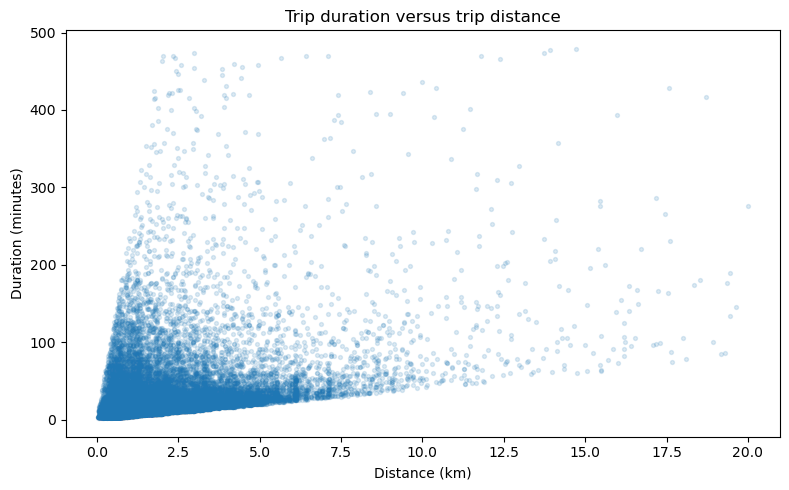

In [103]:
plt.figure(figsize=(8, 5))
trip_plot_sample = trips.sample(n=min(50000, len(trips)), random_state=42)
plt.scatter(trip_plot_sample["distance"] / 1000, trip_plot_sample["duration"] / 60, alpha=0.15, s=8)
plt.title("Trip duration versus trip distance")
plt.xlabel("Distance (km)")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

In [104]:
display(trips[["duration", "distance"]].corr())

,duration,distance
duration,1.000000,0.391023
distance,0.391023,1.000000


In [105]:
trip_summary = trips[["duration", "distance"]].describe(
    percentiles=[.5, .75, .9, .95, .99]
).T
display(trip_summary)

,count,mean,std,min,50%,75%,90%,95%,99%,max
duration,1161376.0,1256.241229,1980.837946,121.000000,720.000000,1200.000000,2340.000000,3960.000000,10200.00000,28740.000000
distance,1161376.0,1791.773844,1495.190508,50.013649,1346.710991,2238.540454,3415.328448,4344.718527,7418.18874,19999.457592


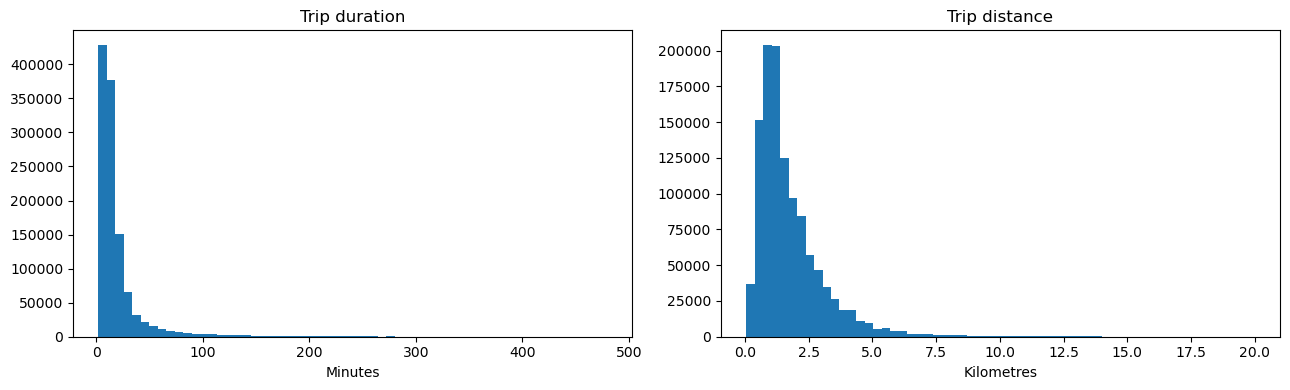

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(trips["duration"] / 60, bins=60)
axes[1].hist(trips["distance"] / 1000, bins=60)
axes[0].set_title("Trip duration")
axes[1].set_title("Trip distance")
axes[0].set_xlabel("Minutes")
axes[1].set_xlabel("Kilometres")
plt.tight_layout()
plt.show()

In [107]:
endpoint_missingness = pd.DataFrame({
    "missing_count": [
        trips["station_id_start"].isna().sum(),
        trips["station_id_end"].isna().sum(),
        trips["battery_start"].isna().sum(),
        trips["battery_end"].isna().sum()
    ],
    "missing_percent": [
        trips["station_id_start"].isna().mean() * 100,
        trips["station_id_end"].isna().mean() * 100,
        trips["battery_start"].isna().mean() * 100,
        trips["battery_end"].isna().mean() * 100
    ]
}, index=["station_id_start", "station_id_end", "battery_start", "battery_end"])
display(endpoint_missingness)

,missing_count,missing_percent
station_id_start,89215,7.681836
station_id_end,121904,10.496514
battery_start,992844,85.488593
battery_end,992735,85.479207


In [108]:
bike_lookup = bike[["id", "bike_type_id"]].rename(columns={"id": "bike_id"})
type_lookup = types[["id", "propulsion_type"]].rename(columns={"id": "bike_type_id"})

In [109]:
trip_profile = trips.merge(
    bike_lookup, on="bike_id", how="left", validate="many_to_one"
).merge(
    type_lookup, on="bike_type_id", how="left", validate="many_to_one"
)

In [110]:
battery_missing_by_propulsion = trip_profile.groupby(
    "propulsion_type", dropna=False
).agg(
    trips=("bike_id", "size"),
    missing_battery_start=("battery_start", lambda x: x.isna().mean() * 100),
    missing_battery_end=("battery_end", lambda x: x.isna().mean() * 100),
    median_battery_start=("battery_start", "median"),
    median_battery_end=("battery_end", "median")
)
display(battery_missing_by_propulsion)

,trips,missing_battery_start,missing_battery_end,median_battery_start,median_battery_end
propulsion_type,,,,,
electric_assist,180091,6.586115,6.52559,89.0,83.0
human,978939,99.969150,99.96915,0.0,0.0
NaN,2346,100.000000,100.00000,NaN,NaN


In [111]:
trip_profile["start_station_missing"] = trip_profile["station_id_start"].isna()
trip_profile["end_station_missing"] = trip_profile["station_id_end"].isna()

In [112]:
free_floating_by_propulsion = trip_profile.groupby(
    "propulsion_type", dropna=False
).agg(
    trips=("bike_id", "size"),
    missing_start_station_percent=("start_station_missing", "mean"),
    missing_end_station_percent=("end_station_missing", "mean")
) * 1
free_floating_by_propulsion[[
    "missing_start_station_percent", "missing_end_station_percent"
]] *= 100
display(free_floating_by_propulsion)

,trips,missing_start_station_percent,missing_end_station_percent
propulsion_type,,,
electric_assist,180091,4.906408,5.995858
human,978939,8.208070,11.346468
NaN,2346,1.150895,1.321398


In [113]:
trip_city = trips.merge(
    city[["id", "name", "country"]],
    left_on="city_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    suffixes=("_trip", "_scheme")
)

In [114]:
trip_city["start_station_missing"] = trip_city["station_id_start"].isna()
trip_city["end_station_missing"] = trip_city["station_id_end"].isna()

In [115]:
free_floating_by_scheme = trip_city.groupby(
    ["city_id", "name", "country"], dropna=False
).agg(
    trips=("time_start", "size"),
    missing_start_station_percent=("start_station_missing", "mean"),
    missing_end_station_percent=("end_station_missing", "mean")
)

In [116]:
free_floating_by_scheme[[
    "missing_start_station_percent", "missing_end_station_percent"
]] *= 100
display(free_floating_by_scheme.sort_values("trips", ascending=False).head(20))

,,,trips,missing_start_station_percent,missing_end_station_percent
city_id,name,country,,,
848,Esplugues de Llobregat,ES,29661,0.000000,0.003371
592,Walldorf,DE,28458,62.896198,67.288636
88,Sursee Plus,CH,28230,9.029401,14.243712
530,Mönchengladbach,DE,27232,4.615893,11.262485
817,Mobic,DE,27073,21.161305,23.647176
856,Sant Boi de Llobregat,ES,26840,0.003726,0.029806
749,Getxo,ES,25874,3.416557,4.804050
496,Koszalin,PL,25160,1.693164,2.062798
251,Lublin,PL,24785,1.468630,2.453097


#### Trip interpretation

#### 5.12 Data preprocessing summary

In [117]:
bike_clean = bike.copy()
types_clean = types.copy()
city_clean = city.copy()
station_clean = station.drop(columns=["rack_locks"]).copy()

In [118]:
station_clean["negative_special_racks_flag"] = station_clean["special_racks"] < 0
station_clean["zero_regular_racks_flag"] = station_clean["bike_racks"] == 0

In [119]:
print("Prepared metadata table shapes:")
for name, df in {
    "bike_clean": bike_clean,
    "types_clean": types_clean,
    "city_clean": city_clean,
    "station_clean": station_clean
}.items():
    print(f"{name:16s} {df.shape}")

print("station_status and trips are preserved in their original variables.")

Prepared metadata table shapes:
bike_clean       (88436, 3)
types_clean      (121, 9)
city_clean       (267, 7)
station_clean    (2932, 12)
station_status and trips are preserved in their original variables.


#### summary log

### Supervised task

The required target is the number of bicycles available for rental at a given station approximately one hour after the current snapshot.

The prediction is: {y_s,t+1h} = f(X_{s,t}) where s = station name, t = current time, X_s,t = info of station at time t, y_s,t+1 = predicting the no of bikes avaialble to rent at that station approx one hour later. 

In [120]:
intervals = status_intervals
near_one_hour = intervals.between(50, 70)

print("Intervals between 50 and 70 minutes:",
      round(near_one_hour.mean() * 100, 2), "%")
print("Median within-station interval (minutes):", intervals.median())
print("Median of station-level median intervals (minutes):",
      station_frequency["median_interval"].median())

Intervals between 50 and 70 minutes: 5.39 %
Median within-station interval (minutes): 28.0
Median of station-level median intervals (minutes): 155.75


In [121]:
TARGET_HORIZON = pd.Timedelta(hours=1)
TARGET_TOLERANCE = pd.Timedelta(minutes=10)

In [122]:
feature_columns = [
    "station_id", "time", "datetime", "bikes", "booked_bikes",
    "bikes_available_to_rent", "free_racks", "free_special_racks",
    "maintenance"
]


In [123]:
model_base = station_status[feature_columns].copy()
model_base = model_base.sort_values(["station_id", "time"])

In [124]:
model_base["previous_available_bikes"] = (
    model_base.groupby("station_id")["bikes_available_to_rent"].shift(1)
)
model_base["previous_booked_bikes"] = (
    model_base.groupby("station_id")["booked_bikes"].shift(1)
)
model_base["minutes_since_previous_observation"] = (
    model_base.groupby("station_id")["time"].diff() / 60
)

In [125]:
model_base["target_time"] = model_base["datetime"] + TARGET_HORIZON
model_base = model_base.sort_values("target_time")

In [126]:
future_target = station_status[
    ["station_id", "datetime", "bikes_available_to_rent"]
].rename(columns={
    "datetime": "matched_target_time",
    "bikes_available_to_rent": "target_available_bikes"
}).sort_values("matched_target_time")

In [127]:
candidate_rows = pd.merge_asof(
    model_base.sort_values("target_time"),
    future_target,
    left_on="target_time",
    right_on="matched_target_time",
    by="station_id",
    direction="nearest",
    tolerance=TARGET_TOLERANCE
)

In [128]:
candidate_rows["actual_horizon_minutes"] = (
    candidate_rows["matched_target_time"] - candidate_rows["datetime"]
).dt.total_seconds() / 60

In [129]:
prediction_data = candidate_rows.dropna(
    subset=["target_available_bikes"]
).copy()

In [130]:
print("Candidate feature rows:", len(model_base))
print("Rows with matched one-hour target:", len(prediction_data))
print("Target coverage (%):",
      round(len(prediction_data) / len(model_base) * 100, 2))
display(prediction_data["actual_horizon_minutes"].describe())

Candidate feature rows: 2925967
Rows with matched one-hour target: 899724
Target coverage (%): 30.75


count    899724.000000
mean         59.843470
std           4.793623
min          50.000000
25%          57.000000
50%          60.000000
75%          63.000000
max          70.000000
Name: actual_horizon_minutes, dtype: float64

In [131]:
prediction_data["hour_utc"] = prediction_data["datetime"].dt.hour
prediction_data["weekday_utc"] = prediction_data["datetime"].dt.dayofweek
prediction_data["month_utc"] = prediction_data["datetime"].dt.month
prediction_data["is_weekend_utc"] = prediction_data["weekday_utc"].isin([5, 6]).astype(int)
prediction_data["hour_sin"] = np.sin(2 * np.pi * prediction_data["hour_utc"] / 24)
prediction_data["hour_cos"] = np.cos(2 * np.pi * prediction_data["hour_utc"] / 24)

In [132]:
station_features = station[[
    "id", "city_id", "terminal_type", "place_type",
    "bike_racks", "special_racks", "lon", "lat"
]].rename(columns={"id": "station_id"})

In [133]:
prediction_data = prediction_data.merge(
    station_features,
    on="station_id",
    how="left",
    validate="many_to_one"
)

In [134]:
city_features = city[["id", "country", "timezone", "return_to_official_only"]].rename(
    columns={"id": "city_id"}
)

In [135]:
prediction_data = prediction_data.merge(
    city_features,
    on="city_id",
    how="left",
    validate="many_to_one"
)

In [136]:
print("Prediction dataset shape:", prediction_data.shape)
display(prediction_data.head())

Prediction dataset shape: (899724, 32)


,station_id,time,datetime,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,previous_available_bikes,...,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat,country,timezone,return_to_official_only
0,33279657,1.661525e+09,2022-08-26 14:48:01+00:00,1,0,1,14,12,False,NaN,...,639,character,0,15,0,19.716100,52.547934,PL,Europe/Warsaw,True
1,322936,1.661525e+09,2022-08-26 14:48:01+00:00,4,0,4,12,11,False,NaN,...,255,character,0,16,0,20.621729,52.109289,PL,Europe/Warsaw,True
2,6495460,1.661525e+09,2022-08-26 14:48:01+00:00,6,0,6,0,0,False,NaN,...,206,free,0,5,0,33.317940,35.166090,CY,Asia/Istanbul,False
3,724351,1.661525e+09,2022-08-26 14:48:01+00:00,14,0,14,17,17,True,NaN,...,320,sign,0,22,0,-0.722220,52.048810,GB,Europe/London,True
4,9799774,1.661525e+09,2022-08-26 14:48:01+00:00,0,0,0,15,14,False,NaN,...,551,7inch,0,15,0,20.437741,52.056359,PL,Europe/Warsaw,True


In [137]:
prediction_data = prediction_data[
    prediction_data["previous_available_bikes"].notna()
].copy()

prediction_data["maintenance"] = prediction_data["maintenance"].astype(int)
prediction_data["return_to_official_only"] = (
    prediction_data["return_to_official_only"].astype(int)
)

prediction_data["negative_special_racks_flag"] = (
    prediction_data["special_racks"] < 0
).astype(int)
prediction_data["special_racks"] = prediction_data["special_racks"].clip(lower=0)
prediction_data["total_declared_racks"] = (
    prediction_data["bike_racks"] + prediction_data["special_racks"]
)

prediction_data["terminal_type"] = (
    prediction_data["terminal_type"].fillna("missing")
)

categorical_cols = ["terminal_type", "country", "timezone"]
prediction_data = pd.get_dummies(
    prediction_data, columns=categorical_cols, drop_first=True
)

prediction_data = prediction_data.drop(columns=["station_id", "city_id"])

In [138]:
target_column = "target_available_bikes"

excluded_from_features = {
    target_column, "matched_target_time", "target_time",
    "actual_horizon_minutes", "datetime", "time"
}

feature_columns_model = [
    col for col in prediction_data.columns
    if col not in excluded_from_features
]

print("Target:", target_column)
print(feature_columns_model)

Target: target_available_bikes
['bikes', 'booked_bikes', 'bikes_available_to_rent', 'free_racks', 'free_special_racks', 'maintenance', 'previous_available_bikes', 'previous_booked_bikes', 'minutes_since_previous_observation', 'hour_utc', 'weekday_utc', 'month_utc', 'is_weekend_utc', 'hour_sin', 'hour_cos', 'place_type', 'bike_racks', 'special_racks', 'lon', 'lat', 'return_to_official_only', 'negative_special_racks_flag', 'total_declared_racks', 'terminal_type_character', 'terminal_type_free', 'terminal_type_missing', 'terminal_type_mmt', 'terminal_type_pult', 'terminal_type_sign', 'terminal_type_smart_sign', 'terminal_type_stele', 'terminal_type_terminal_sleek', 'terminal_type_traffic_sign', 'country_CH', 'country_CY', 'country_CZ', 'country_DE', 'country_ES', 'country_GB', 'country_HR', 'country_LV', 'country_MT', 'country_PL', 'country_SI', 'timezone_Atlantic/Canary', 'timezone_Europe/Berlin', 'timezone_Europe/Brussels', 'timezone_Europe/London', 'timezone_Europe/Riga', 'timezone_Eur

In [141]:
print("Prediction rows:", len(prediction_data))
#print("Unique stations:", prediction_data["station_id"].nunique())
print("Feature timestamp range:",
      prediction_data["datetime"].min(),
      "to",
      prediction_data["datetime"].max())
print("Target timestamp range:",
      prediction_data["matched_target_time"].min(),
      "to",
      prediction_data["matched_target_time"].max())
display(prediction_data[feature_columns_model + [target_column]].isna().mean()
        .sort_values(ascending=False).rename("missing_fraction"))

Prediction rows: 899412
Feature timestamp range: 2022-08-26 14:49:01+00:00 to 2023-07-15 21:08:01+00:00
Target timestamp range: 2022-08-26 15:45:01+00:00 to 2023-07-15 21:59:01+00:00


bikes                                 0.0
booked_bikes                          0.0
terminal_type_sign                    0.0
terminal_type_smart_sign              0.0
terminal_type_stele                   0.0
terminal_type_terminal_sleek          0.0
terminal_type_traffic_sign            0.0
country_CH                            0.0
country_CY                            0.0
country_CZ                            0.0
country_DE                            0.0
country_ES                            0.0
country_GB                            0.0
country_HR                            0.0
country_LV                            0.0
country_MT                            0.0
country_PL                            0.0
country_SI                            0.0
timezone_Atlantic/Canary              0.0
timezone_Europe/Berlin                0.0
timezone_Europe/Brussels              0.0
timezone_Europe/London                0.0
timezone_Europe/Riga                  0.0
timezone_Europe/Rome              

In [142]:
prediction_data = prediction_data.sort_values("datetime")
cutoff = prediction_data["datetime"].quantile(0.8)

train = prediction_data[prediction_data["datetime"] < cutoff].copy()
valid = prediction_data[prediction_data["datetime"] >= cutoff].copy()

X_train = train[feature_columns_model]
y_train = train[target_column]
X_valid = valid[feature_columns_model]
y_valid = valid[target_column]

In [143]:
baseline_pred = valid["bikes_available_to_rent"].values
baseline_mae  = mean_absolute_error(y_valid, baseline_pred)
baseline_rmse = mean_squared_error(y_valid, baseline_pred) ** 0.5

In [144]:
model = HistGradientBoostingRegressor(
    max_iter=400,
    learning_rate=0.05,
    max_depth=None,
    random_state=42
)
model.fit(X_train, y_train)
model_pred = np.clip(model.predict(X_valid), 0, None)


In [145]:
model_mae  = mean_absolute_error(y_valid, model_pred)
model_rmse = mean_squared_error(y_valid, model_pred) ** 0.5

print(f"Baseline MAE:  {baseline_mae:.3f}")
print(f"Model MAE:     {model_mae:.3f}")
print(f"Baseline RMSE: {baseline_rmse:.3f}")
print(f"Model RMSE:    {model_rmse:.3f}")
print(f"Skill (1 - MAE_model / MAE_baseline): "
      f"{1 - model_mae / baseline_mae:.3f}")

Baseline MAE:  1.623
Model MAE:     1.567
Baseline RMSE: 2.466
Model RMSE:    2.207
Skill (1 - MAE_model / MAE_baseline): 0.034


In [146]:
valid = valid.assign(pred=model_pred, baseline=baseline_pred)

error_by_flag = valid.groupby("negative_special_racks_flag").apply(
    lambda g: pd.Series({
        "n": len(g),
        "model_MAE": mean_absolute_error(g[target_column], g["pred"]),
        "baseline_MAE": mean_absolute_error(g[target_column], g["baseline"]),
    })
)
display(error_by_flag)

/var/folders/qp/vwvz5t5x67b8cp19vx8yc7km0000gn/T/ipykernel_2895/2316912160.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_by_flag = valid.groupby("negative_special_racks_flag").apply(


,n,model_MAE,baseline_MAE
negative_special_racks_flag,,,
0,177515.0,1.574975,1.633513
1,2379.0,0.969370,0.801597


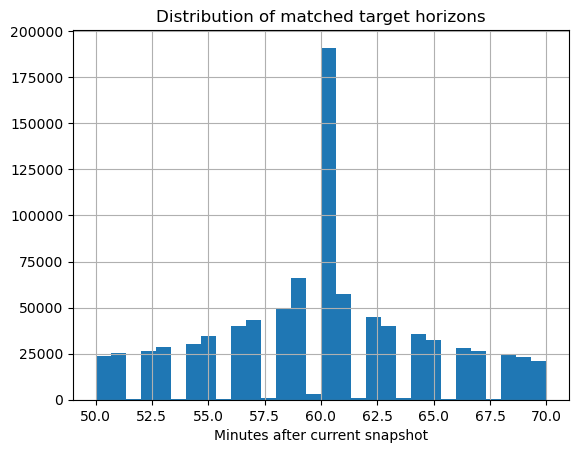

In [147]:
prediction_data["actual_horizon_minutes"].hist(bins=30)
plt.title("Distribution of matched target horizons")
plt.xlabel("Minutes after current snapshot")
plt.show()